In [2]:
!pip install -q ultralytics opencv-python

In [3]:
import torch
import cv2
from ultralytics import YOLO

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("OpenCV version:", cv2.__version__)
print("YOLO imported successfully!")

GPU available: True
GPU: Tesla T4
OpenCV version: 4.14.0
YOLO imported successfully!


In [4]:
from ultralytics import YOLO
import torch

model = YOLO("yolov8n.pt")

device = 0 if torch.cuda.is_available() else "cpu"

print("Model loaded successfully!")
print("Running on:", "GPU" if device == 0 else "CPU")

Model loaded successfully!
Running on: GPU


In [16]:
from google.colab import files

uploaded = files.upload()

Saving 15001976_2160_3840_30fps.mp4 to 15001976_2160_3840_30fps.mp4


In [18]:
import cv2
import os

video_path = next(iter(uploaded.keys()))

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("ERROR: Could not open video")
else:
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    print("Video:", video_path)
    print("Resolution:", width, "x", height)
    print("FPS:", fps)
    print("Total frames:", total_frames)
    print("Duration (seconds):", round(total_frames / fps, 2) if fps else "Unknown")

cap.release()

Video: 15001976_2160_3840_30fps.mp4
Resolution: 2160 x 3840
FPS: 30.0
Total frames: 325
Duration (seconds): 10.83


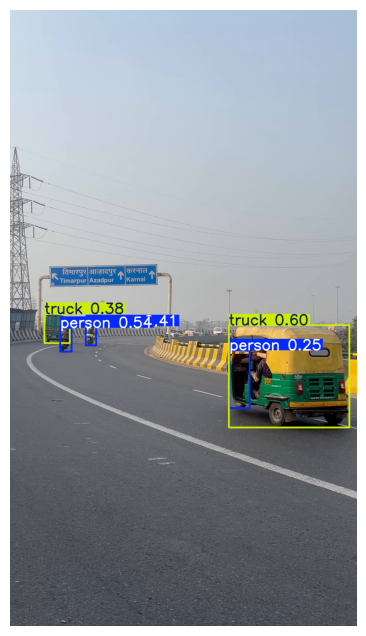

Detected objects: 5
Labels: ['truck', 'person', 'person', 'truck', 'person']


In [19]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

if ret:
    results = model.predict(
        source=frame,
        imgsz=640,
        conf=0.25,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )

    annotated = results[0].plot()

    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

    print("Detected objects:", len(results[0].boxes))
    print("Labels:", [model.names[int(c)] for c in results[0].boxes.cls])
else:
    print("Could not read the video. Check video_path.")

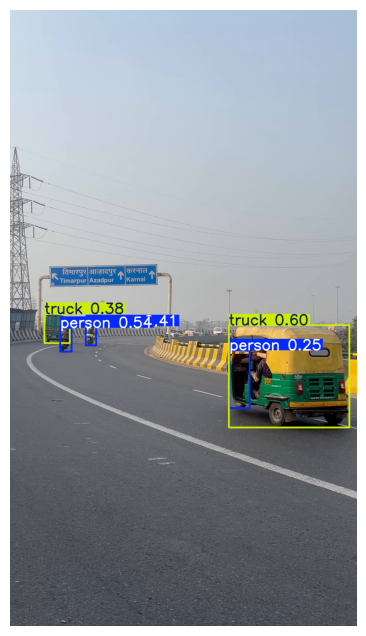

In [20]:
import matplotlib.pyplot as plt
import cv2

annotated = results[0].plot()

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [28]:
from ultralytics import YOLO
import torch
import os

input_video = "/content/15001976_2160_3840_30fps.mp4"

model = YOLO("yolov8s.pt")

results = model.predict(
    source=input_video,
    imgsz=640,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    save=True,
    project="/content/runs",
    name="correct_video_detection",
    exist_ok=True,
    stream=True,
    verbose=False
)

for i, result in enumerate(results, start=1):
    if i % 50 == 0:
        print(f"Processed {i} frames")

print("Detection completed!")

Processed 50 frames
Processed 100 frames
Processed 150 frames
Processed 200 frames
Processed 250 frames
Processed 300 frames
Results saved to /content/runs/correct_video_detection
Detection completed!


In [30]:
import glob
from google.colab import files

outputs = glob.glob(
    "/content/runs/correct_video_detection/*.avi"
) + glob.glob(
    "/content/runs/correct_video_detection/*.mp4"
)

print("Generated files:", outputs)

if outputs:
    files.download(outputs[0])
else:
    print("No output found. Send me the output above.")

Generated files: ['/content/runs/correct_video_detection/15001976_2160_3840_30fps.avi']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import os
import cv2
from google.colab import files

output_path = (
    "/content/runs/correct_video_detection/"
    "15001976_2160_3840_30fps.avi"
)

print("File exists:", os.path.exists(output_path))

if os.path.exists(output_path):
    cap = cv2.VideoCapture(output_path)

    print("Video opens:", cap.isOpened())
    print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Resolution:",
          int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x",
          int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

    cap.release()
else:
    print("Output missing. Check the path before rerunning detection.")

File exists: True
Video opens: True
Frame count: 325
FPS: 30.0
Resolution: 2160 x 3840


In [33]:
from google.colab import files

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>